# Analisis Performa HVAC (AHU/FCU) & Manajemen Risiko Kondensasi pada Ruang Peralatan Medis

Notebook ini berisi rangkaian analisis termal, psikrometrik, serta sensitivitas aliran udara (*airflow*) dan kelembapan ruangan terhadap risiko kondensasi permukaan pada peralatan medis sensitif.

--

***Moch Nur Jamalludin - 2026***

**BF ( Bypass Factor Calculation )** yaitu presentasi udara yang melewati coil namun tidak terkondisikan secara sempurna sampai mencapai Apparatus Dew Point ( ADP ). Semakin kecil BF semakin efektif performa coil.

**KETERANGAN**

T_ADP = Apparatus DewPoint,yaitu temperatur efektik permukaan coil

T_R = Temperature return Air

T_S = Temperature Supply Air ( diambil sedekat mungkin dari coil )

BF = Bypass Factor

Diffuser airflow = debit udara supply


###DATA LAPANGAN :

In [24]:
T_S = 11 #<-- ganti dengan nilai pengukuran
T_ADP = 8 #<-- ganti dengan nilai pengukuran
T_R = 23 #<-- ganti dengan nilai pengukuran
airflow_cfm = 400 #<-- ganti dengan nilai pengukuran

### **Parameter Tambahan Kelembapan (Humidity)**

Untuk menghitung Beban Laten dan Kapasitas Total secara akurat, kita memerlukan data kelembapan relatif (%RH) dari udara masuk (Return) dan udara keluar (Supply).

In [25]:
# Tambahkan input kelembapan relatif (RH) untuk perhitungan Laten & Total
RH_R = 55  # Kelembapan relatif udara Return (%)
RH_S = 90  # Kelembapan relatif udara Supply (%)

### **Pembaruan Fungsi Analisis Performa HVAC**

Fungsi ini sekarang menghitung entalpi udara menggunakan temperatur dan RH untuk mendapatkan Kapasitas Pendinginan Total ($Q_t$), Kapasitas Sensibel ($Q_s$), dan Kapasitas Laten ($Q_l = Q_t - Q_s$).

In [26]:
def kalkulasi_entalpi(T, RH):
    # Pendekatan praktis menghitung tekanan uap jenuh (kPa) menggunakan persamaan Magnus-Tetens
    p_sat = 0.61078 * np.exp((17.27 * T) / (T + 237.3))
    # Tekanan uap aktual (kPa)
    p_w = p_sat * (RH / 100.0)
    # Rasio kelembapan (kg air / kg udara kering)
    p_atm = 101.325 # Tekanan atmosfer standar
    w = 0.62194 * p_w / (p_atm - p_w)
    # Entalpi (kJ/kg udara kering)
    h = 1.006 * T + w * (2501 + 1.86 * T)
    # Konversi kJ/kg ke BTU/lb
    h_btu_lb = h * 0.429923
    return h_btu_lb

def analisis_performa_hvac_lengkap(T_R, T_S, T_ADP, RH_R, RH_S, airflow_cfm):
    # 1. Menghitung Bypass Factor (BF) dan Contact Factor (CF)
    bf = (T_S - T_ADP) / (T_R - T_ADP)
    cf = 1 - bf

    # Kerapatan udara standar ~ 0.075 lb/cu.ft
    # Laju aliran massa udara (lb/hr) = CFM * 60 * 0.075 = CFM * 4.5

    # 2. Menghitung Entalpi
    h_R = kalkulasi_entalpi(T_R, RH_R)
    h_S = kalkulasi_entalpi(T_S, RH_S)

    # 3. Kapasitas Total (Q_t)
    q_t = 4.5 * airflow_cfm * (h_R - h_S)
    q_t_tr = q_t / 12000

    # 4. Kapasitas Sensibel (Q_s)
    q_s = 1.08 * airflow_cfm * (T_R - T_S)
    q_s_tr = q_s / 12000

    # 5. Kapasitas Laten (Q_l)
    q_l = q_t - q_s
    q_l_tr = q_l / 12000

    # Sensible Heat Ratio (SHR)
    shr = q_s / q_t if q_t > 0 else 0

    print(f"=== HASIL ANALISIS PERFORMA HVAC LENGKAP ===")
    print(f"Bypass Factor (BF)      : {bf*100:.2f}%")
    print(f"Contact Factor (CF)     : {cf*100:.2f}%")
    print(f"--------------------------------------------")
    print(f"Total Cooling Capacity  : {q_t:.2f} BTU/hr ({q_t_tr:.2f} TR)")
    print(f"Sensible Capacity (Qs)  : {q_s:.2f} BTU/hr ({q_s_tr:.2f} TR)")
    print(f"Latent Capacity (Ql)    : {q_l:.2f} BTU/hr ({q_l_tr:.2f} TR)")
    print(f"Sensible Heat Ratio(SHR): {shr:.2f}")
    print(f"--------------------------------------------")

    if bf > 0.20:
        print("Evaluasi: Bypass Factor tinggi (>20%). Kontak udara kurang optimal.")
    else:
        print("Evaluasi: Kontak udara pada coil pendingin sudah sangat baik.")

analisis_performa_hvac_lengkap(T_R, T_S, T_ADP, RH_R, RH_S, airflow_cfm)

=== HASIL ANALISIS PERFORMA HVAC LENGKAP ===
Bypass Factor (BF)      : 20.00%
Contact Factor (CF)     : 80.00%
--------------------------------------------
Total Cooling Capacity  : 13984.52 BTU/hr (1.17 TR)
Sensible Capacity (Qs)  : 5184.00 BTU/hr (0.43 TR)
Latent Capacity (Ql)    : 8800.52 BTU/hr (0.73 TR)
Sensible Heat Ratio(SHR): 0.37
--------------------------------------------
Evaluasi: Kontak udara pada coil pendingin sudah sangat baik.


### **Analisis Performa HVAC (AHU & FCU)**

Untuk menganalisis performa *Air Handling Unit* (AHU) atau *Fan Coil Unit* (FCU), beberapa parameter utama yang perlu dievaluasi adalah:

1. **Bypass Factor (BF):** Persentase udara yang melewati coil tanpa mengalami pengkondisian (kontak langsung dengan permukaan coil).
2. **Contact Factor (CF):** Persentase udara yang bersentuhan langsung dan terkondisikan oleh coil. $CF = 1 - BF$.
3. **Kapasitas Pendinginan Total ($Q_t$):** Laju perpindahan panas total yang diserap oleh coil pendingin (Sensibel + Laten).
4. **Kapasitas Sensibel ($Q_s$):** Laju penurunan temperatur udara tanpa perubahan kadar air.
5. **Kapasitas Laten ($Q_l$):** Laju pengurangan kadar air (kelembapan) melalui proses kondensasi.



In [27]:
def analisis_performa_hvac(T_R, T_S, T_ADP, airflow_cfm):
    # 1. Menghitung Bypass Factor (BF) dan Contact Factor (CF)
    bf = (T_S - T_ADP) / (T_R - T_ADP)
    cf = 1 - bf

    # 2. Estimasi Sensible Cooling Capacity (Q_s) dalam BTU/hr
    # Rumus praktis: Q_s = 1.08 * CFM * (T_Return - T_Supply)
    q_s = 1.08 * airflow_cfm * (T_R - T_S)

    # Konversi BTU/hr ke TR (Tons of Refrigeration)
    q_s_tr = q_s / 12000

    print(f"=== HASIL ANALISIS PERFORMA ===")
    print(f"Bypass Factor (BF)  : {bf*100:.2f}%")
    print(f"Contact Factor (CF) : {cf*100:.2f}%")
    print(f"Sensible Capacity   : {q_s:.2f} BTU/hr ({q_s_tr:.2f} TR)")

    if bf > 0.20:
        print("\nEvaluasi: Bypass Factor cukup tinggi (> 20%). Performa coil kurang optimal, udara banyak yang lolos tanpa terkondisikan.")
    else:
        print("\nEvaluasi: Performa coil sangat baik. Kontak udara dengan permukaan pendingin optimal.")

# # Contoh Parameter Operasional
# T_R = 23      # Temperatur Return (C)
# T_S = 11      # Temperatur Supply (C)
# T_ADP = 8     # Apparatus Dew Point (C)
# airflow = 1500 # Airflow dlm CFM (contoh kapasitas sedang)

analisis_performa_hvac(T_R, T_S, T_ADP, airflow)

=== HASIL ANALISIS PERFORMA ===
Bypass Factor (BF)  : 20.00%
Contact Factor (CF) : 80.00%
Sensible Capacity   : 19440.00 BTU/hr (1.62 TR)

Evaluasi: Performa coil sangat baik. Kontak udara dengan permukaan pendingin optimal.


### **Analisis Sensitivitas: Pengaruh Airflow terhadap Kapasitas Pendinginan**

Grafik di bawah ini menunjukkan bagaimana kapasitas pendinginan sensibel ($Q_s$ dalam TR atau Ton of Refrigeration) berubah secara linear seiring dengan perubahan laju aliran udara (*airflow* dalam CFM), dengan asumsi perbedaan temperatur ($T_{return} - T_{supply}$) tetap konstan.

### **Refaktorisasi Fungsi Analisis Sensitivitas**

Fungsi di bawah ini dirancang agar menerima parameter `min_cfm`, `max_cfm`, serta langkah pembagiannya, sehingga kita dapat dengan mudah menguji berbagai rentang spesifikasi AHU/FCU.

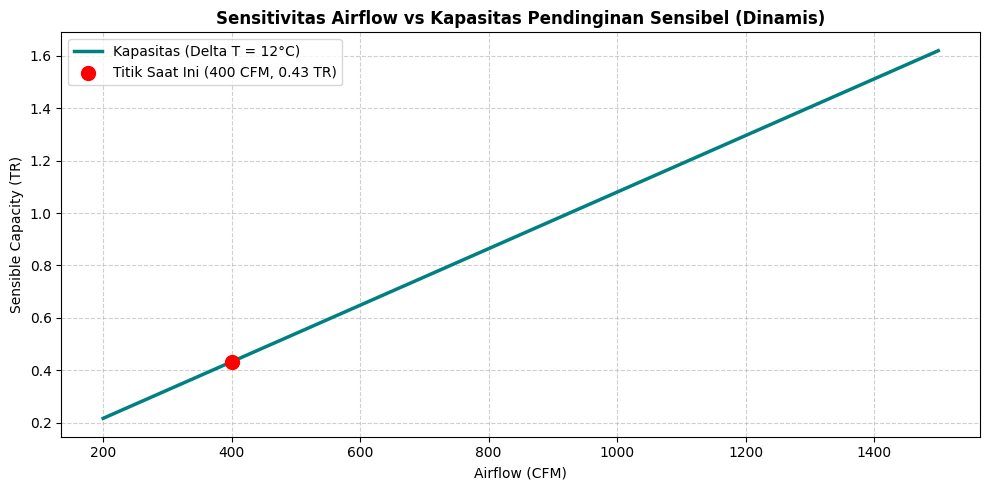

In [28]:
def plot_sensitivitas_airflow(T_R, T_S, current_airflow_cfm, min_cfm=100, max_cfm=2000, num_steps=50):
    import numpy as np
    import matplotlib.pyplot as plt

    # Membuat rentang airflow berdasarkan input parameter
    cfms_custom = np.linspace(min_cfm, max_cfm, num_steps)

    # Menghitung kapasitas sensibel (TR)
    delta_T = T_R - T_S
    q_s_tr_custom = (1.08 * cfms_custom * delta_T) / 12000

    # Menghitung titik operasional saat ini
    current_q_s_tr = (1.08 * current_airflow_cfm * delta_T) / 12000

    # Membuat plot
    plt.figure(figsize=(10, 5))
    plt.plot(cfms_custom, q_s_tr_custom, color='teal', linewidth=2.5,
             label=f'Kapasitas (Delta T = {delta_T}°C)')

    # Menandai titik saat ini jika berada di dalam rentang grafik
    if min_cfm <= current_airflow_cfm <= max_cfm:
        plt.scatter(current_airflow_cfm, current_q_s_tr, color='red', s=100, zorder=5,
                    label=f'Titik Saat Ini ({current_airflow_cfm} CFM, {current_q_s_tr:.2f} TR)')

    plt.title('Sensitivitas Airflow vs Kapasitas Pendinginan Sensibel (Dinamis)', fontsize=12, fontweight='bold')
    plt.xlabel('Airflow (CFM)', fontsize=10)
    plt.ylabel('Sensible Capacity (TR)', fontsize=10)
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.legend(loc='upper left')
    plt.tight_layout()
    plt.show()

# Menjalankan fungsi dengan rentang custom (Contoh: 200 hingga 1500 CFM)
plot_sensitivitas_airflow(T_R, T_S, airflow_cfm, min_cfm=200, max_cfm=1500)

### **Visualisasi Sensitivitas Kapasitas Total, Sensibel, dan Laten terhadap Airflow**

Grafik di bawah ini membandingkan pengaruh perubahan *airflow* (CFM) terhadap ketiga komponen kapasitas pendinginan sekaligus ($Q_t$, $Q_s$, dan $Q_l$ dalam TR).

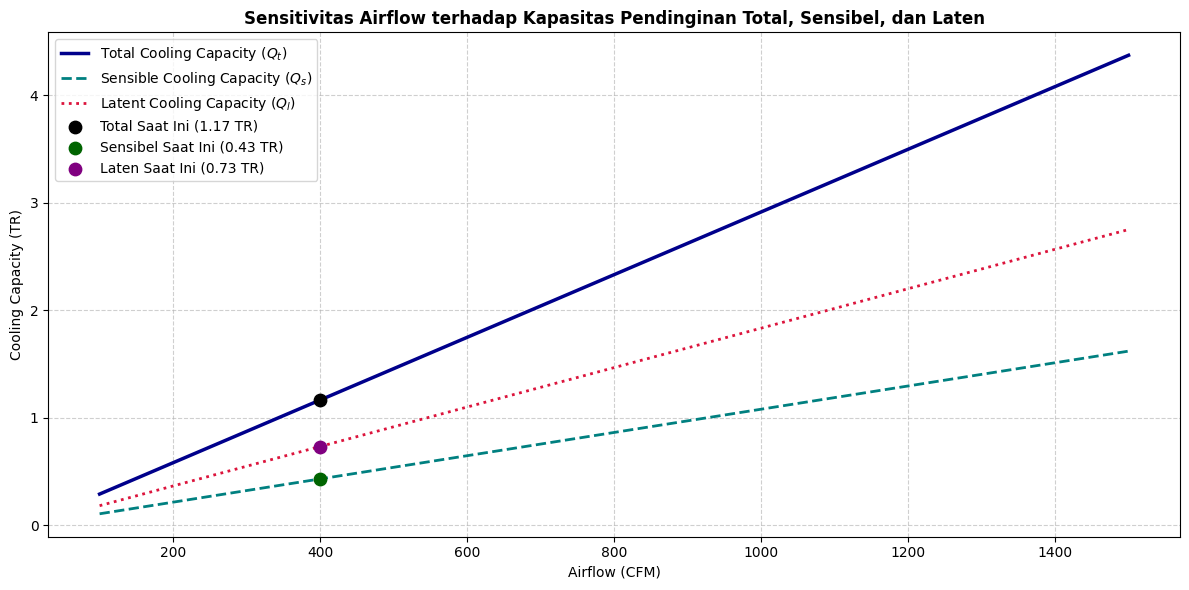

In [29]:
def plot_sensitivitas_kapasitas_lengkap(T_R, T_S, RH_R, RH_S, current_airflow_cfm, min_cfm=100, max_cfm=2000, num_steps=50):
    import numpy as np
    import matplotlib.pyplot as plt

    # Menghitung entalpi konstan
    h_R = kalkulasi_entalpi(T_R, RH_R)
    h_S = kalkulasi_entalpi(T_S, RH_S)

    # Rentang airflow (CFM)
    cfms = np.linspace(min_cfm, max_cfm, num_steps)

    # Menghitung kapasitas (TR)
    q_t_tr = (4.5 * cfms * (h_R - h_S)) / 12000
    q_s_tr = (1.08 * cfms * (T_R - T_S)) / 12000
    q_l_tr = q_t_tr - q_s_tr

    # Titik saat ini
    curr_q_t = (4.5 * current_airflow_cfm * (h_R - h_S)) / 12000
    curr_q_s = (1.08 * current_airflow_cfm * (T_R - T_S)) / 12000
    curr_q_l = curr_q_t - curr_q_s

    # Membuat Plot
    plt.figure(figsize=(12, 6))
    plt.plot(cfms, q_t_tr, color='darkblue', linewidth=2.5, label='Total Cooling Capacity ($Q_t$)')
    plt.plot(cfms, q_s_tr, color='teal', linewidth=2, linestyle='--', label='Sensible Cooling Capacity ($Q_s$)')
    plt.plot(cfms, q_l_tr, color='crimson', linewidth=2, linestyle=':', label='Latent Cooling Capacity ($Q_l$)')

    # Menandai titik operasional saat ini
    if min_cfm <= current_airflow_cfm <= max_cfm:
        plt.scatter(current_airflow_cfm, curr_q_t, color='black', s=80, zorder=5, label=f'Total Saat Ini ({curr_q_t:.2f} TR)')
        plt.scatter(current_airflow_cfm, curr_q_s, color='darkgreen', s=80, zorder=5, label=f'Sensibel Saat Ini ({curr_q_s:.2f} TR)')
        plt.scatter(current_airflow_cfm, curr_q_l, color='purple', s=80, zorder=5, label=f'Laten Saat Ini ({curr_q_l:.2f} TR)')

    plt.title('Sensitivitas Airflow terhadap Kapasitas Pendinginan Total, Sensibel, dan Laten', fontsize=12, fontweight='bold')
    plt.xlabel('Airflow (CFM)', fontsize=10)
    plt.ylabel('Cooling Capacity (TR)', fontsize=10)
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.legend(loc='upper left')
    plt.tight_layout()
    plt.show()

# Menjalankan visualisasi
plot_sensitivitas_kapasitas_lengkap(T_R, T_S, RH_R, RH_S, airflow_cfm, min_cfm=100, max_cfm=1500)

### **Analisis Kenyamanan Pengguna (Human Comfort) & Keamanan Peralatan Medis**

Berdasarkan data operasional saat ini:
* **Kondisi Ruangan (Return Air):** $T_R = 23^\circ\text{C}$ dan $\text{RH}_R = 55\%$
* **Kondisi Udara Masuk (Supply Air):** $T_S = 11^\circ\text{C}$ dan $\text{RH}_S = 90\%$
* **Sensible Heat Ratio (SHR):** $0.37$ (Kapasitas pendinginan didominasi oleh penyerapan beban laten/kelembapan)

Berikut adalah analisis dampak kondisi tersebut terhadap pengguna ruangan serta peralatan medis/elektronik:

---

#### **1. Analisis Terhadap Kenyamanan Pengguna (Human Comfort)**
Berdasarkan standar **ASHRAE 55** (Thermal Environmental Conditions for Human Occupancy):
* **Temperatur ($23^\circ\text{C}$):** Berada di zona nyaman ideal untuk aktivitas ringan dalam ruangan ($22^\circ\text{C}$ hingga $24^\circ\text{C}$).
* **Kelembapan ($55\% \text{ RH}$):** Sangat ideal. Batas nyaman manusia adalah antara $30\%$ hingga $60\% \text{ RH}$. Kelembapan $55\%$ mencegah kulit dan saluran pernapasan menjadi kering tanpa membuat ruangan terasa pengap.
* **Kualitas Udara:** Supply air yang dingin ($11^\circ\text{C}$) harus dipastikan terdistribusi dengan baik menggunakan diffuser agar tidak menimbulkan efek *draft* (hembusan angin dingin langsung) yang mengganggu kenyamanan termal lokal.

---

#### **2. Analisis Terhadap Peralatan Medis & Elektronik Sensitif**
Peralatan medis (seperti MRI, CT Scan, USG) dan perangkat ruang server memiliki regulasi ketat berdasarkan standar **ASHRAE TC 9.9**:
* **Potensi Kondensasi (Kondensasi Permukaan):**
  * Udara ruangan berada pada $23^\circ\text{C}$ dengan $55\% \text{ RH}$, yang memiliki **Dew Point (Titik Embun) sekitar $13.5^\circ\text{C}$**.
  * Karena udara *Supply* keluar sangat dingin ($11^\circ\text{C}$), setiap permukaan logam atau casing peralatan medis yang terkena langsung aliran udara supply $11^\circ\text{C}$ akan mendingin di bawah $13.5^\circ\text{C}$.
  * **Risiko Tinggi:** Hal ini dapat memicu terbentuknya **embun/kondensasi** pada permukaan luar atau bagian dalam komponen elektronik sensitif, yang dapat menyebabkan korsleting elektrik atau korosi.
* **Kelembapan Relatif ($55\%$):** Sangat aman untuk mencegah penumpukan listrik statis (terjadi jika $\text{RH} < 40\%$) dan mencegah pertumbuhan jamur/korosi cepat (terjadi jika $\text{RH} > 60\%$).

---

### **Rekomendasi Operasional & Mitigasi**
1. **Arah Aliran Udara:** Pastikan udara *Supply* ($11^\circ\text{C}$) tidak mengarah langsung ke fisik alat medis sensitif. Gunakan deflektor udara jika perlu.
2. **Monitoring Titik Embun:** Jaga agar temperatur permukaan alat medis selalu di atas temperatur titik embun ruangan ($13.5^\circ\text{C}$).
3. **Suhu Supply:** Jika memungkinkan, naikkan sedikit temperatur *Supply* ke $13^\circ\text{C} - 14^\circ\text{C}$ untuk memperkecil gap temperatur dan mengurangi risiko kondensasi, selama kapasitas pendinginan ruangan masih terpenuhi.

### **Analisis & Rekomendasi Temperatur Supply Udara ($T_S$) untuk Menghindari Kondensasi**

Titik embun (*Dew Point*, $T_{dp}$) adalah temperatur di mana udara harus didinginkan agar uap air di dalamnya mulai mengembun menjadi tetesan air.

Jika temperatur permukaan suatu alat medis berada di bawah temperatur titik embun udara sekitar, kondensasi akan terjadi pada alat tersebut. Oleh karena itu, temperatur udara keluar (*Supply*) dari AHU/FCU sebaiknya dijaga berada di atas titik embun ruangan ditambah dengan batas aman (*safety margin*).

In [30]:
import numpy as np
import matplotlib.pyplot as plt

def hitung_dew_point(T, RH):
    # Menggunakan rumus Magnus-Tetens untuk pendekatan akurat Dew Point
    a = 17.27
    b = 237.7
    alpha = ((a * T) / (b + T)) + np.log(RH / 100.0)
    T_dp = (b * alpha) / (a - alpha)
    return T_dp

# 1. Hitung Dew Point Ruangan Saat Ini
T_dp_ruangan = hitung_dew_point(T_R, RH_R)

# 2. Definisikan Safety Margin (Standar industri menyarankan 1.0°C hingga 2.0°C di atas Dew Point)
safety_margin = 1.5
T_S_optimal_min = T_dp_ruangan + safety_margin

print(f"=== REKOMENDASI TEMPERATUR SUPPLY AMAN ===")
print(f"Temperatur Ruangan (Return)       : {T_R:.1f} °C")
print(f"Kelembapan Ruangan (Return)       : {RH_R:.1f} %")
print(f"Titik Embun Ruangan (Dew Point)   : {T_dp_ruangan:.2f} °C")
print(f"Batas Aman Minimum Supply Air (T_S): {T_S_optimal_min:.2f} °C (Dew Point + {safety_margin}°C Margin)")
print(f"Temperatur Supply Saat Ini        : {T_S:.1f} °C")

if T_S < T_dp_ruangan:
    print(f"\n[BAHAYA] Temperatur supply saat ini ({T_S}°C) berada di bawah Dew Point ({T_dp_ruangan:.2f}°C). Kondensasi PASTI terjadi pada permukaan logam yang kontak langsung.")
elif T_S < T_S_optimal_min:
    print(f"\n[PERINGATAN] Temperatur supply saat ini ({T_S}°C) terlalu dekat dengan Dew Point. Direkomendasikan naik ke minimal {T_S_optimal_min:.1f}°C.")
else:
    print(f"\n[AMAN] Temperatur supply saat ini ({T_S}°C) berada di zona aman bebas kondensasi.")

=== REKOMENDASI TEMPERATUR SUPPLY AMAN ===
Temperatur Ruangan (Return)       : 23.0 °C
Kelembapan Ruangan (Return)       : 55.0 %
Titik Embun Ruangan (Dew Point)   : 13.46 °C
Batas Aman Minimum Supply Air (T_S): 14.96 °C (Dew Point + 1.5°C Margin)
Temperatur Supply Saat Ini        : 11.0 °C

[BAHAYA] Temperatur supply saat ini (11°C) berada di bawah Dew Point (13.46°C). Kondensasi PASTI terjadi pada permukaan logam yang kontak langsung.


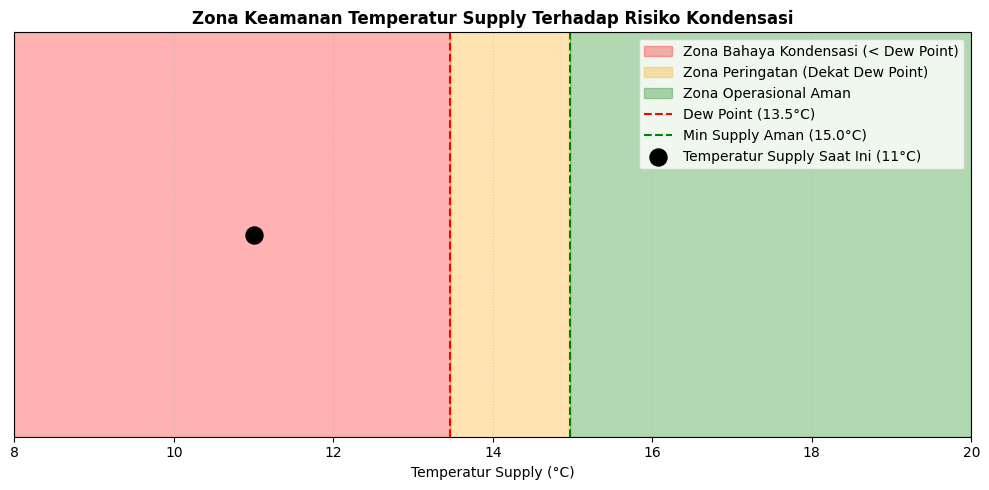

In [31]:
# Visualisasi Batas Aman Temperatur Supply
temperatures = np.linspace(8, 20, 100)

plt.figure(figsize=(10, 5))
# Zona Bahaya (Di bawah Dew Point)
plt.axvspan(8, T_dp_ruangan, color='red', alpha=0.3, label='Zona Bahaya Kondensasi (< Dew Point)')
# Zona Peringatan (Antara Dew Point & Margin Aman)
plt.axvspan(T_dp_ruangan, T_S_optimal_min, color='orange', alpha=0.3, label='Zona Peringatan (Dekat Dew Point)')
# Zona Aman
plt.axvspan(T_S_optimal_min, 20, color='green', alpha=0.3, label='Zona Operasional Aman')

# Garis penanda
plt.axvline(T_dp_ruangan, color='red', linestyle='--', linewidth=1.5, label=f'Dew Point ({T_dp_ruangan:.1f}°C)')
plt.axvline(T_S_optimal_min, color='green', linestyle='--', linewidth=1.5, label=f'Min Supply Aman ({T_S_optimal_min:.1f}°C)')

# Plot titik supply saat ini
plt.scatter(T_S, 0.5, color='black', s=150, zorder=5, label=f'Temperatur Supply Saat Ini ({T_S}°C)')

plt.title('Zona Keamanan Temperatur Supply Terhadap Risiko Kondensasi', fontsize=12, fontweight='bold')
plt.xlabel('Temperatur Supply (°C)', fontsize=10)
plt.yticks([]) # Menghilangkan sumbu y karena hanya visualisasi range
plt.xlim(8, 20)
plt.grid(True, axis='x', linestyle=':', alpha=0.5)
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

### **Analisis Sensitivitas: Pengaruh Kelembapan Relatif (RH) terhadap Titik Embun (Dew Point)**

Grafik di bawah ini memvisualisasikan bagaimana temperatur Titik Embun berubah seiring dengan naik-turunnya kelembapan relatif (RH) di dalam ruangan, menggunakan temperatur ruangan saat ini ($T_R = 23^\circ\text{C}$) sebagai konstanta.

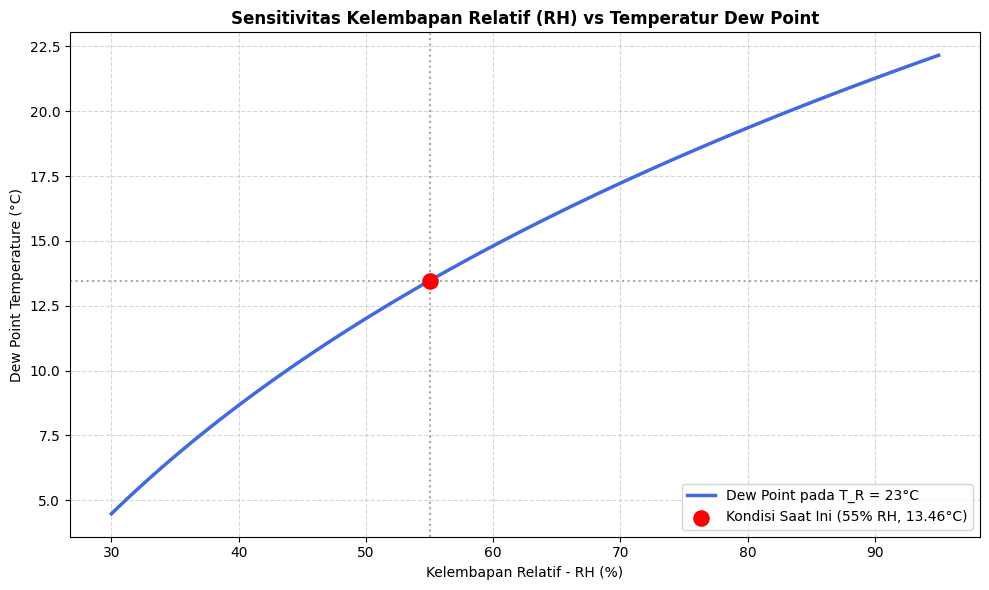

In [32]:
# Definisikan rentang kelembapan relatif dari 30% hingga 95%
rh_range = np.linspace(30, 95, 100)

# Hitung Dew Point untuk setiap nilai RH pada T_R = 23 C
dew_points = [hitung_dew_point(T_R, rh) for rh in rh_range]

# Membuat Plot
plt.figure(figsize=(10, 6))
plt.plot(rh_range, dew_points, color='royalblue', linewidth=2.5, label=f'Dew Point pada T_R = {T_R}°C')

# Tandai kondisi kelembapan aktual saat ini (RH_R = 55%)
plt.scatter(RH_R, T_dp_ruangan, color='red', s=120, zorder=5,
            label=f'Kondisi Saat Ini ({RH_R}% RH, {T_dp_ruangan:.2f}°C)')

# Tambahkan garis bantu untuk kondisi aktual
plt.axvline(RH_R, color='gray', linestyle=':', alpha=0.7)
plt.axhline(T_dp_ruangan, color='gray', linestyle=':', alpha=0.7)

plt.title('Sensitivitas Kelembapan Relatif (RH) vs Temperatur Dew Point', fontsize=12, fontweight='bold')
plt.xlabel('Kelembapan Relatif - RH (%)', fontsize=10)
plt.ylabel('Dew Point Temperature (°C)', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

### **Kalkulasi & Visualisasi Batas Aman Temperatur Supply Terhadap Variasi Kelembapan (RH)**

Untuk memastikan ruangan bebas dari kondensasi pada berbagai tingkat kelembapan ruangan, grafik di bawah ini memetakan **Minimum Safe Supply Temperature** ($T_{S,\text{safe}} = T_{dp} + 1.5^\circ\text{C}$ margin) langsung terhadap perubahan kelembapan relatif (RH) dari 30% hingga 90% pada temperatur ruangan tetap $23^\circ\text{C}$.

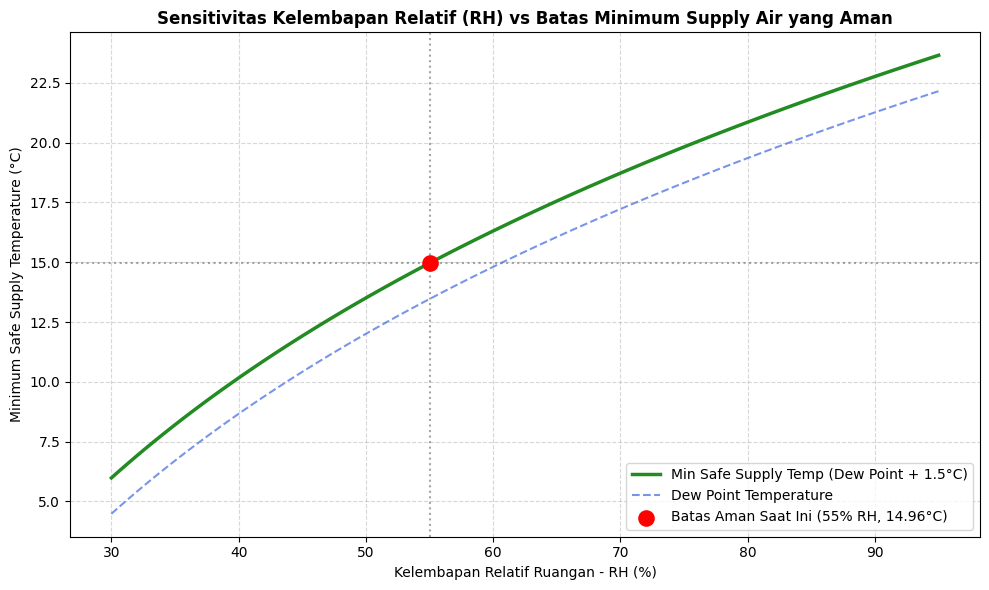

In [33]:
# Hitung batas aman minimum temperatur supply untuk setiap nilai RH
safe_supply_temps = [hitung_dew_point(T_R, rh) + safety_margin for rh in rh_range]

# Membuat Plot
plt.figure(figsize=(10, 6))
plt.plot(rh_range, safe_supply_temps, color='forestgreen', linewidth=2.5,
         label=f'Min Safe Supply Temp (Dew Point + {safety_margin}°C)')

# Menampilkan Dew Point sebagai referensi
plt.plot(rh_range, dew_points, color='royalblue', linestyle='--', alpha=0.7,
         label='Dew Point Temperature')

# Tandai titik kondisi operasional ruangan saat ini (RH_R = 55%)
plt.scatter(RH_R, T_S_optimal_min, color='red', s=120, zorder=5,
            label=f'Batas Aman Saat Ini ({RH_R}% RH, {T_S_optimal_min:.2f}°C)')

# Tambahkan garis bantu untuk kondisi aktual
plt.axvline(RH_R, color='gray', linestyle=':', alpha=0.7)
plt.axhline(T_S_optimal_min, color='gray', linestyle=':', alpha=0.7)

plt.title('Sensitivitas Kelembapan Relatif (RH) vs Batas Minimum Supply Air yang Aman', fontsize=12, fontweight='bold')
plt.xlabel('Kelembapan Relatif Ruangan - RH (%)', fontsize=10)
plt.ylabel('Minimum Safe Supply Temperature (°C)', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

### **Analisis Sensitivitas Multi-Variabel: Pengaruh Temperatur Ruangan ($T_R$) & Kelembapan Relatif ($RH$) terhadap Batas Aman Supply Air**

Untuk membandingkan risiko kondensasi secara komprehensif, grafik di bawah ini memetakan batas minimum temperatur *supply* udara yang aman ($T_{S,\text{safe}} = T_{dp} + 1.5^\circ\text{C}$ margin) di berbagai tingkat temperatur ruangan ($20^\circ\text{C}$ hingga $26^\circ\text{C}$) pada rentang kelembapan relatif $30\%$ hingga $90\%$.

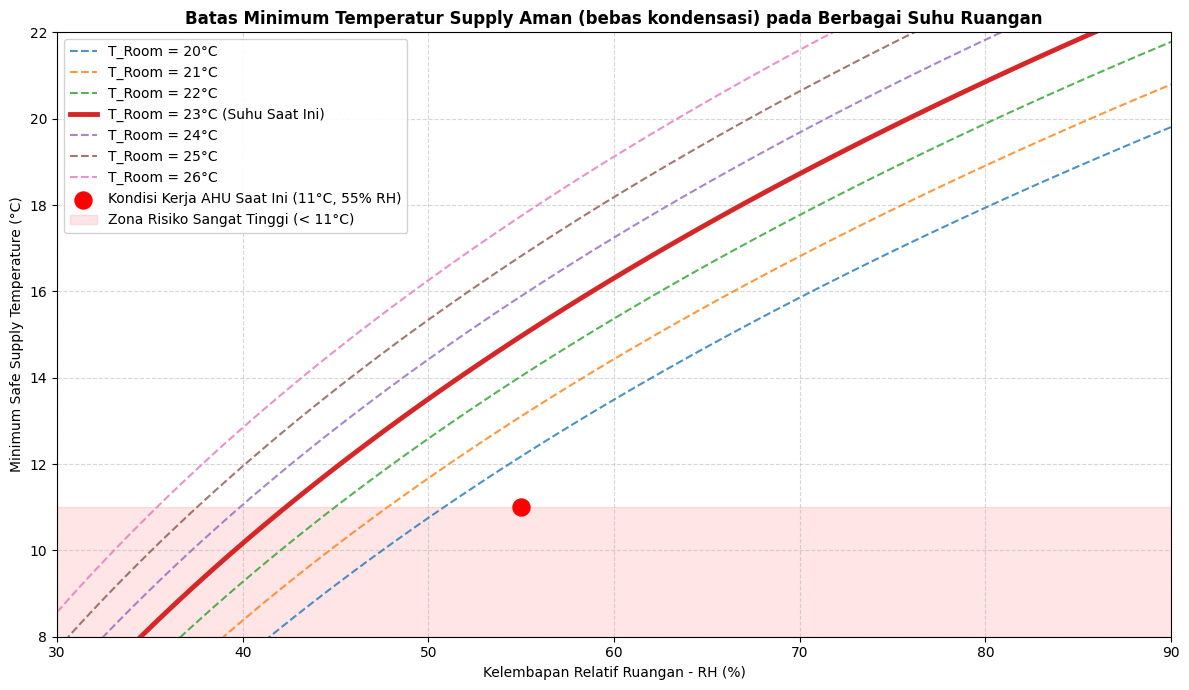

In [34]:
import numpy as np
import matplotlib.pyplot as plt

# Definisikan rentang kelembapan relatif (RH) dari 30% hingga 90%
rh_vals = np.linspace(30, 90, 100)

# Beberapa skenario temperatur ruangan (T_R) yang akan dibandingkan
temperatur_ruangan_skenario = [20, 21, 22, 23, 24, 25, 26]
safety_margin = 1.5

plt.figure(figsize=(12, 7))

# Menghitung dan melakukan plot untuk setiap skenario temperatur ruangan
for t_r in temperatur_ruangan_skenario:
    safe_temps = []
    for rh in rh_vals:
        t_dp = hitung_dew_point(t_r, rh)
        safe_temps.append(t_dp + safety_margin)

    # Gunakan penanda khusus atau ketebalan garis berbeda untuk kondisi aktual saat ini (T_R = 23)
    if t_r == 23:
        plt.plot(rh_vals, safe_temps, label=f'T_Room = {t_r}°C (Suhu Saat Ini)', linewidth=3.5, linestyle='-')
    else:
        plt.plot(rh_vals, safe_temps, label=f'T_Room = {t_r}°C', alpha=0.8, linestyle='--')

# Menandai titik operasional aktual saat ini (T_R = 23, RH_R = 55%, T_S = 11)
plt.scatter(55, 11, color='red', s=150, zorder=5, label='Kondisi Kerja AHU Saat Ini (11°C, 55% RH)')

# Zona bahaya absolut kondensasi untuk skenario terendah (T_Room = 20C)
# Di bawah temperatur supply 10-12 C pada umumnya rentan kondensasi
plt.axhspan(8, 11, color='red', alpha=0.1, label='Zona Risiko Sangat Tinggi (< 11°C)')

plt.title('Batas Minimum Temperatur Supply Aman (bebas kondensasi) pada Berbagai Suhu Ruangan', fontsize=12, fontweight='bold')
plt.xlabel('Kelembapan Relatif Ruangan - RH (%)', fontsize=10)
plt.ylabel('Minimum Safe Supply Temperature (°C)', fontsize=10)
plt.xlim(30, 90)
plt.ylim(8, 22)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='upper left', frameon=True, facecolor='white', framealpha=0.9)
plt.tight_layout()
plt.show()